# Visualize Wadi Gaza change results

Load saved all-years results and create figures. Most figures focus on Wadi Gaza
for the selected `PLOT_INDEX`; the monthly small-multiple, site-by-year-pair
heatmap, and correlogram figures are generated for every configured index and
study area. This notebook does not recompute statistics. For the method, see the
[Mean Index Change Confidence Intervals white paper](../docs/white-papers/Mean-Index-Change-Confidence-Intervals.md).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from change_ci.config import AnalysisConfig
from change_ci.plotting import (
    plot_change_heatmap,
    plot_change_small_multiples,
    plot_change_timeseries,
    plot_correlogram,
    plot_n_eff,
    save_figure,
)
from plot_style import add_title, finish_panel_grid, month_name, site_order

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"
ANALYSIS_CONFIG = AnalysisConfig.from_yaml(
    ROOT / "configs" / "change_ci.yaml", project_root=ROOT
)

## Load saved outputs

In [2]:
PLOT_INDEX = "NDVI"
if PLOT_INDEX not in ANALYSIS_CONFIG.index_bands:
    raise ValueError(f"Index is not configured: {PLOT_INDEX}")
RESULTS_DIR = ANALYSIS_CONFIG.output_dir / PLOT_INDEX
PLOT_DIR = RESULTS_DIR / 'plots'
results = pd.read_csv(RESULTS_DIR / 'results.csv')
correlograms = pd.read_csv(RESULTS_DIR / 'correlograms.csv')
primary = results.loc[results['is_primary_tau']].copy()
wadi = primary.loc[primary['study_area'] == 'WadiGaza'].copy()
print(f'{len(primary)} primary results overall; {len(wadi)} for WadiGaza; {len(correlograms)} correlogram rows')

168 primary results overall; 24 for WadiGaza; 12576 correlogram rows


## WadiGaza mean change by month and year pair

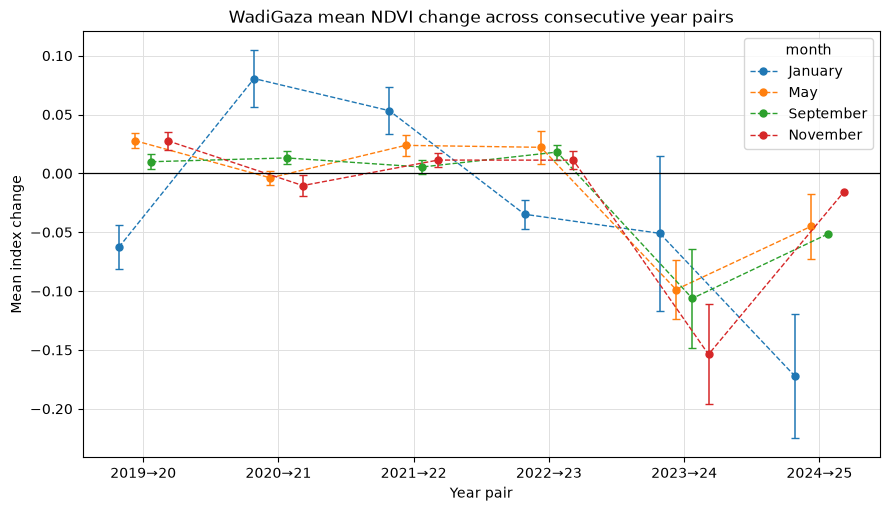

In [3]:
fig, ax = plot_change_timeseries(
    wadi, group_by='month', show_ci_for='all',
)
add_title(ax, f'WadiGaza mean {PLOT_INDEX} change across consecutive year pairs')
save_figure(fig, PLOT_DIR / 'WadiGaza_mean_change_timeseries.png')
plt.show()

## Monthly small multiples

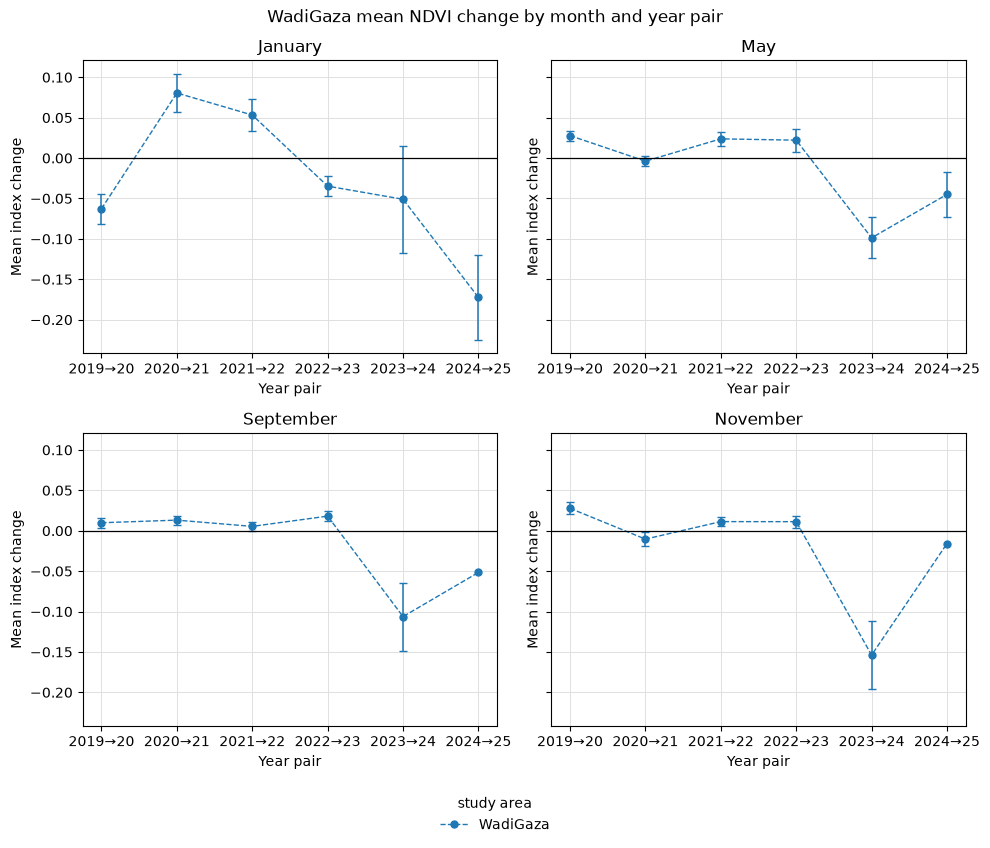

Month-panel figures saved for every study area under each index plots/ folder


In [4]:
MONTH_PANEL_SHOW = {('WadiGaza', PLOT_INDEX)}  # (study_area, index) pairs displayed inline

for index_band in ANALYSIS_CONFIG.index_bands:
    index_results = pd.read_csv(ANALYSIS_CONFIG.output_dir / index_band / 'results.csv')
    index_primary = index_results.loc[index_results['is_primary_tau']].copy()
    index_plot_dir = ANALYSIS_CONFIG.output_dir / index_band / 'plots'
    for study_area in sorted(index_primary['study_area'].astype(str).unique()):
        fig, axes = plot_change_small_multiples(
            index_primary, facet_by='month', filters={'study_area': study_area}, ncols=2,
        )
        add_title(fig, f'{study_area} mean {index_band} change by month and year pair', y=1.02)
        save_figure(fig, index_plot_dir / f'{study_area}_{index_band}_mean_change_month_panels.png')
        if (study_area, index_band) in MONTH_PANEL_SHOW:
            plt.show()
        else:
            plt.close(fig)

print('Month-panel figures saved for every study area under each index plots/ folder')


## Monthly small multiples: WadiGaza vs other areas (2023 to 2024)

Each panel compares study areas for one month. Whiskers are adjusted 95% CIs; pairs flagged for no range retain their mean marker without CI whiskers. WadiGaza is highlighted.

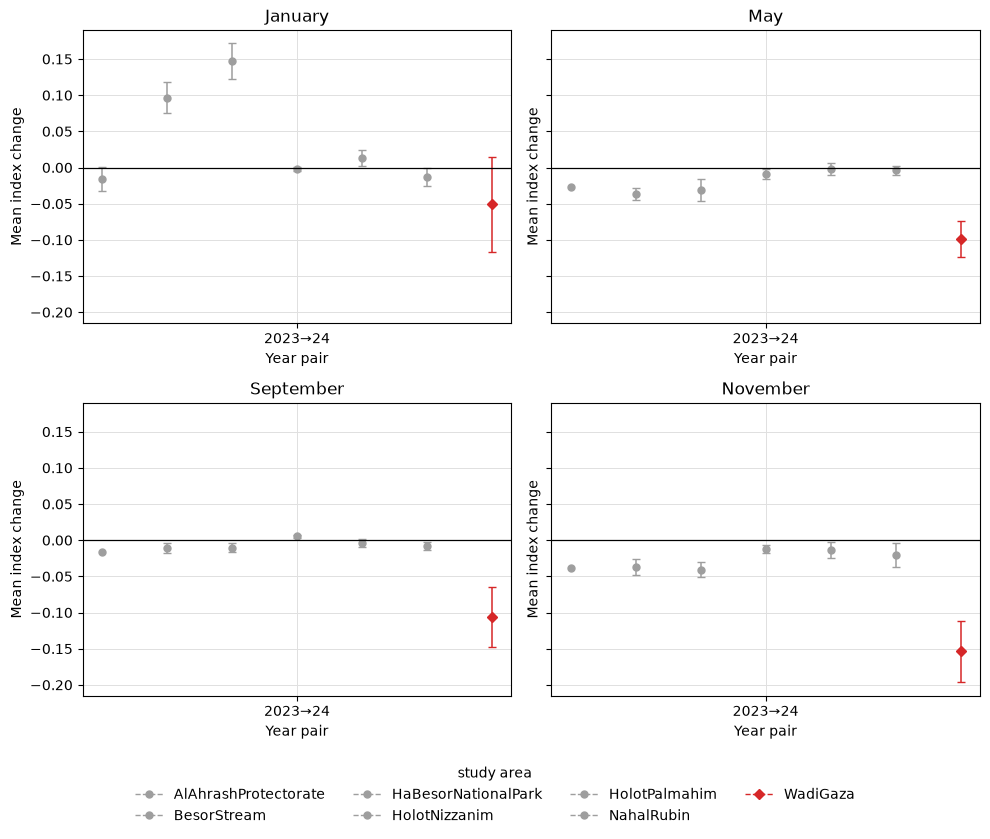

In [5]:
comparison_2023_2024 = primary.loc[
    (primary['year_start'] == 2023) & (primary['year_end'] == 2024)
].copy()
fig, axes = plot_change_small_multiples(
    comparison_2023_2024,
    facet_by='month',
    show_ci_for='all',
    ncols=2,
    highlight='WadiGaza',
)
save_figure(fig, PLOT_DIR / 'WadiGaza_vs_other_areas_2023_2024_monthly_small_multiples.png')
plt.show()

## Site-by-year-pair heatmaps by month for all indices

One figure per configured index; each panel shows mean change for every study
area and consecutive year pair in one month. A shared zero-centered color scale,
shown by one colorbar, makes the four month panels directly comparable; brown is
a decrease and teal an increase. An asterisk marks adjusted 95% CIs that exclude
zero. Figures are saved to each index's `plots/` folder as
`study_area_mean_change_heatmaps.png`.


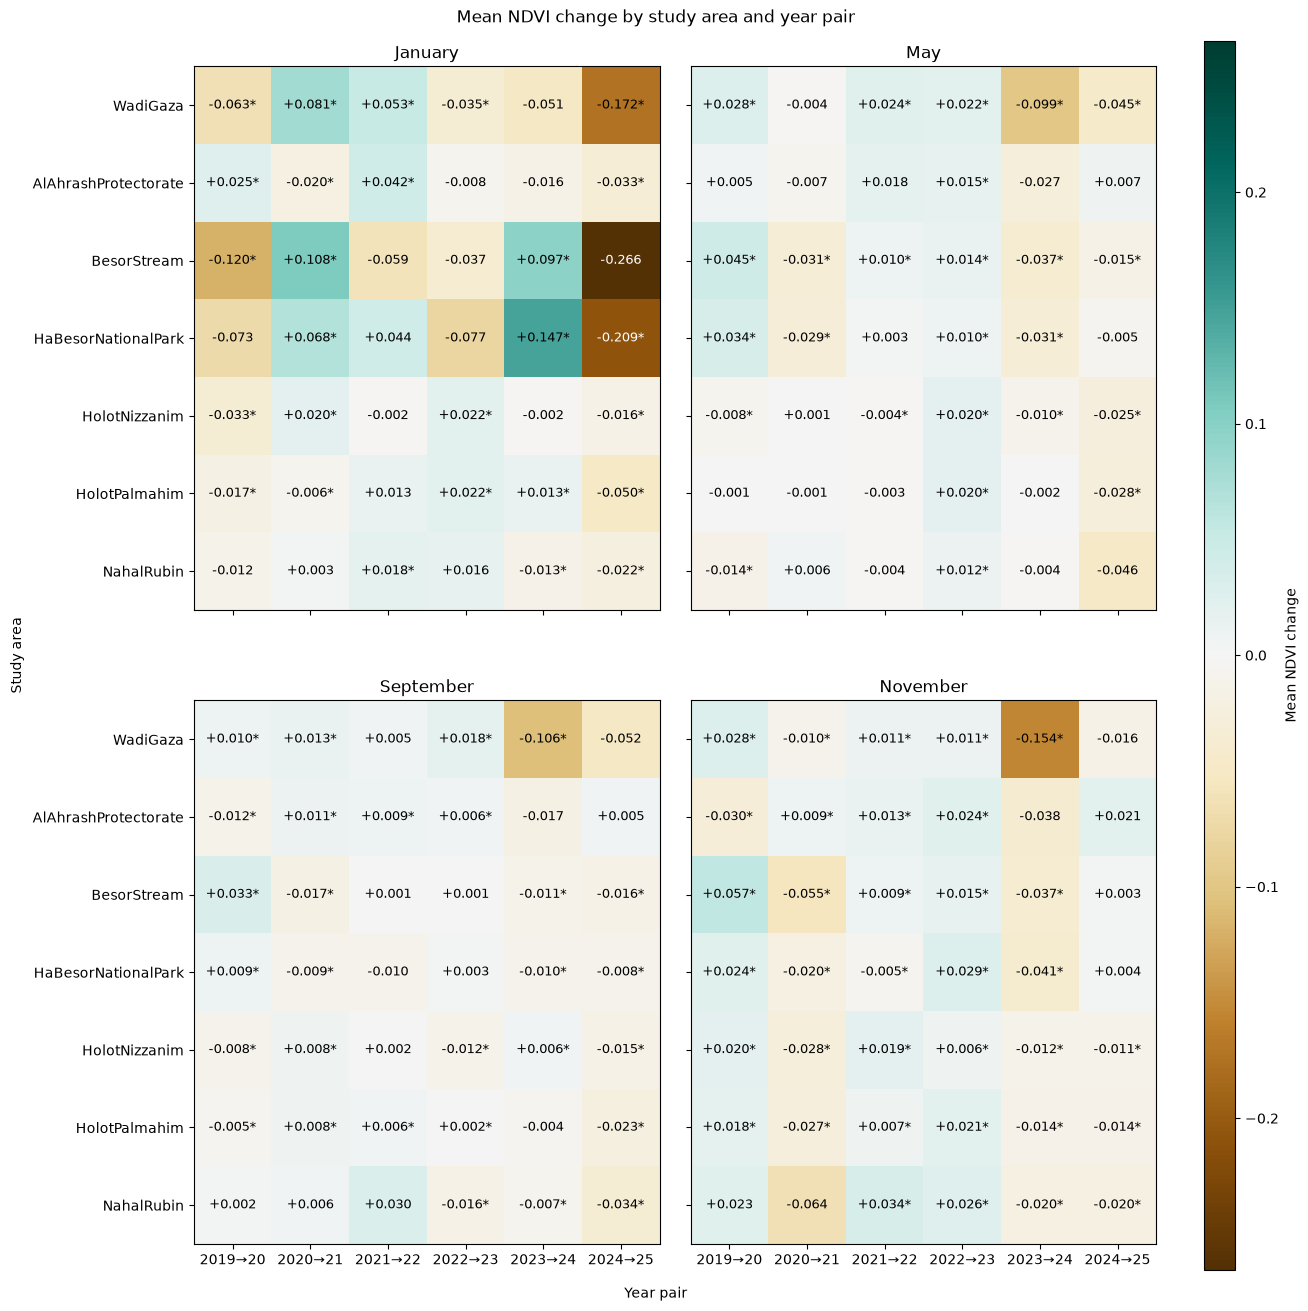

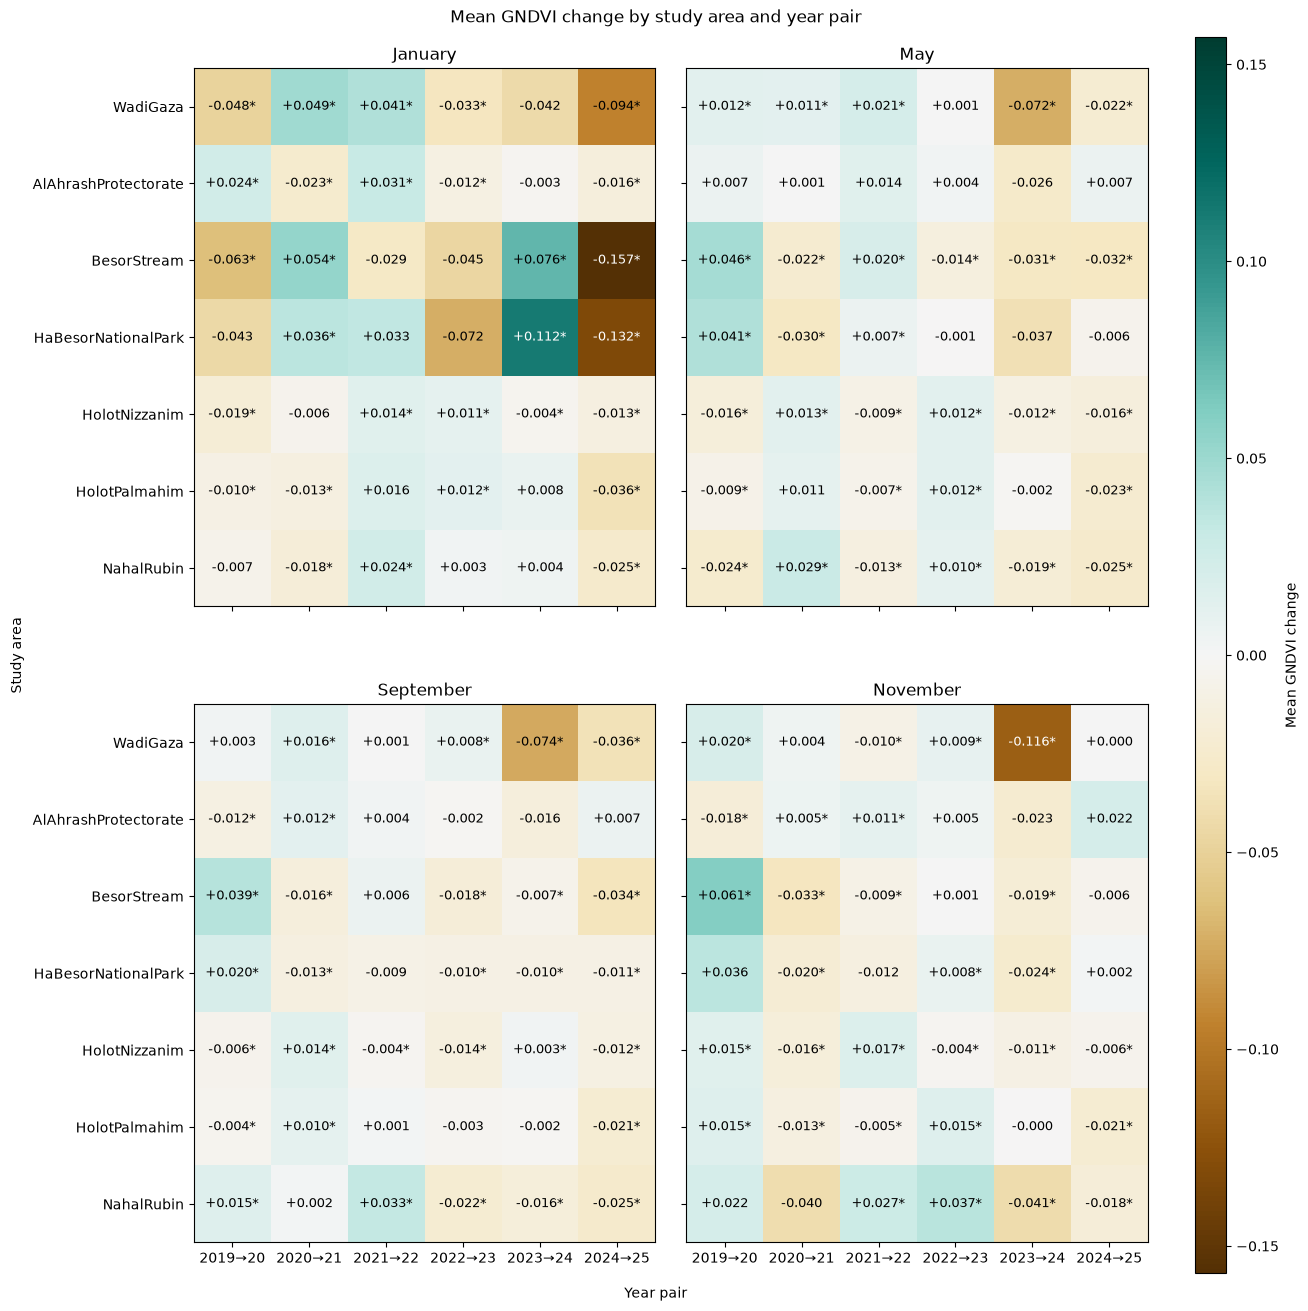

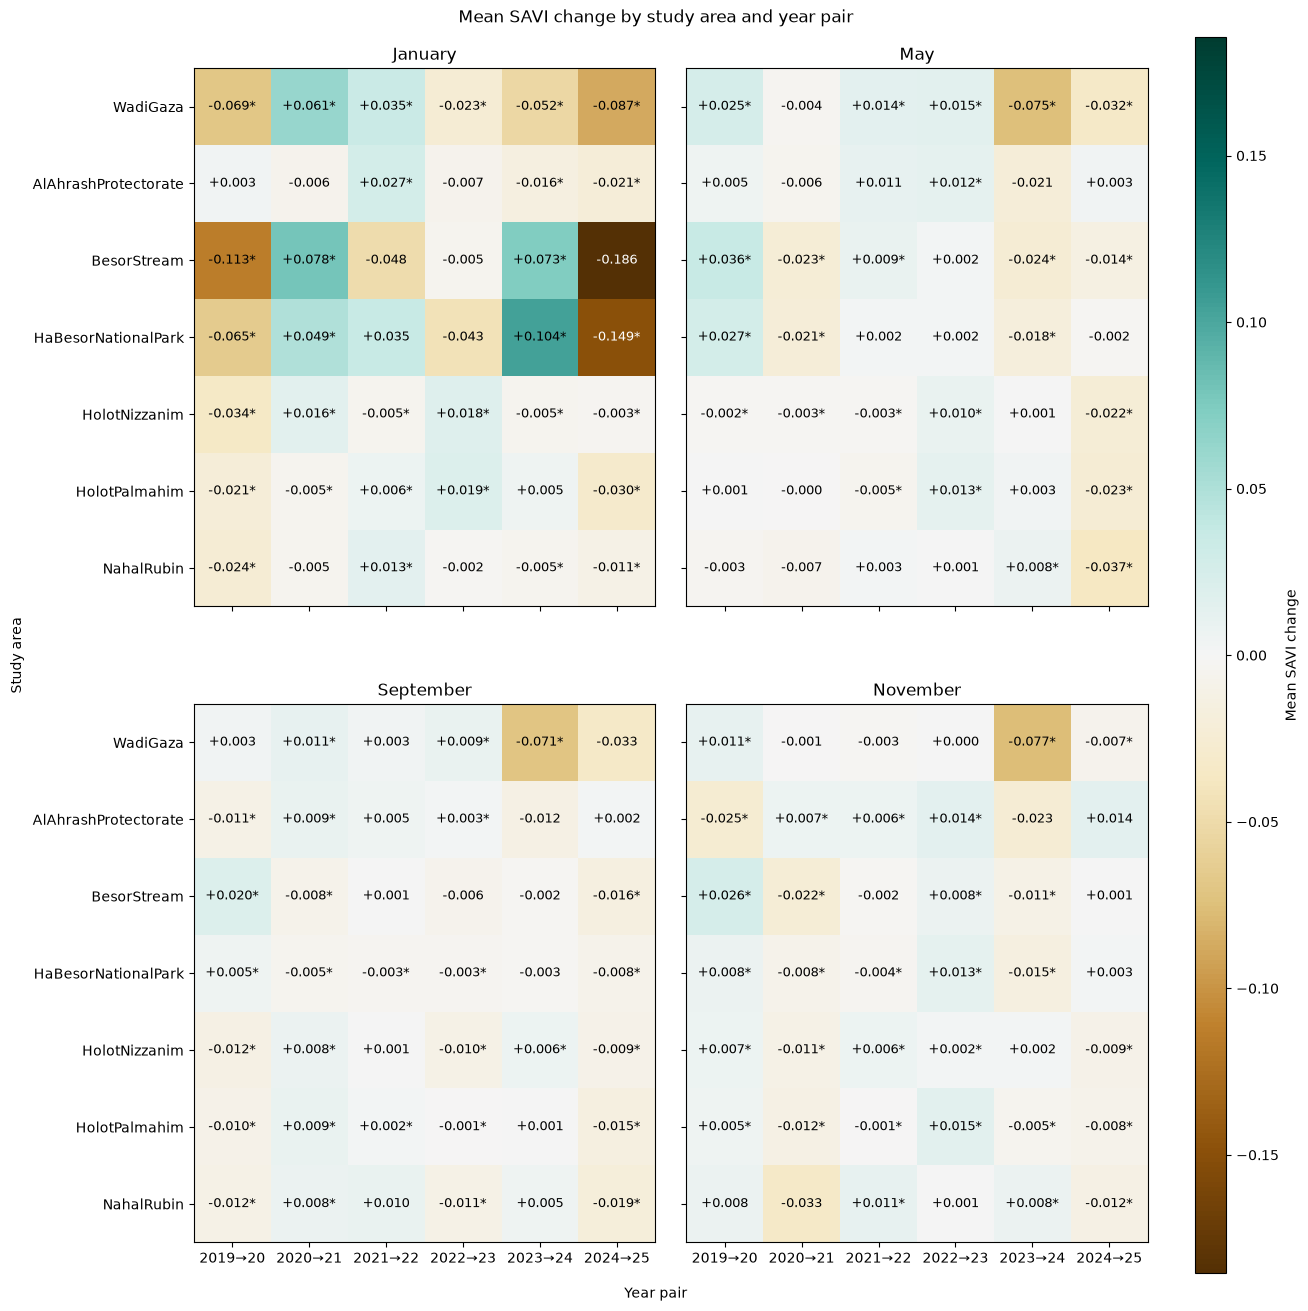

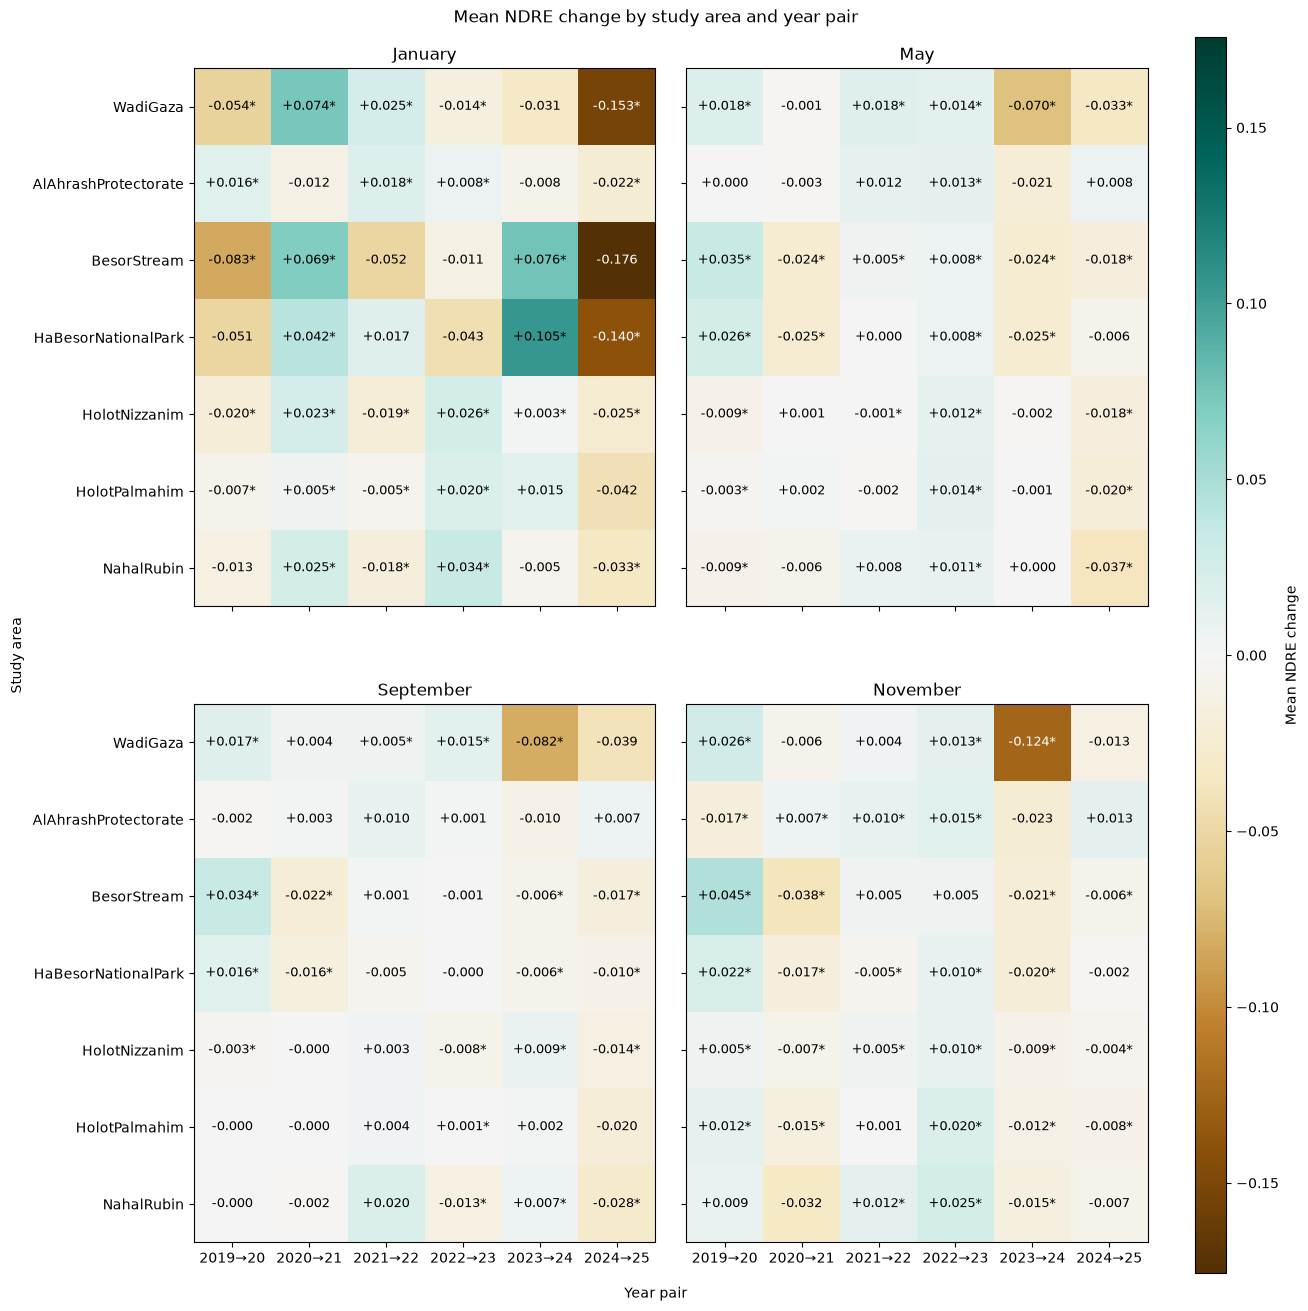

In [6]:
for index_band in ANALYSIS_CONFIG.index_bands:
    index_results = pd.read_csv(ANALYSIS_CONFIG.output_dir / index_band / 'results.csv')
    index_primary = index_results.loc[index_results['is_primary_tau']].copy()
    heatmap_areas = site_order(index_primary['study_area'], 'WadiGaza')
    heatmap_months = sorted({f'{int(m):02d}' for m in index_primary['month']})
    limit = float(index_primary['mean_change'].abs().max())
    fig, axes = plt.subplots(2, 2, figsize=(13, 13), constrained_layout=True)
    for ax, month in zip(axes.flat, heatmap_months):
        plot_change_heatmap(index_primary, month, ax=ax, sites=heatmap_areas, limit=limit, colorbar=False)
        ax.set_title(month_name(month))
    finish_panel_grid(
        fig, axes, label=f'Mean {index_band} change',
        title=f'Mean {index_band} change by study area and year pair',
    )
    save_figure(fig, ANALYSIS_CONFIG.output_dir / index_band / 'plots' / 'study_area_mean_change_heatmaps.png')
    plt.show()


## WadiGaza effective sample size

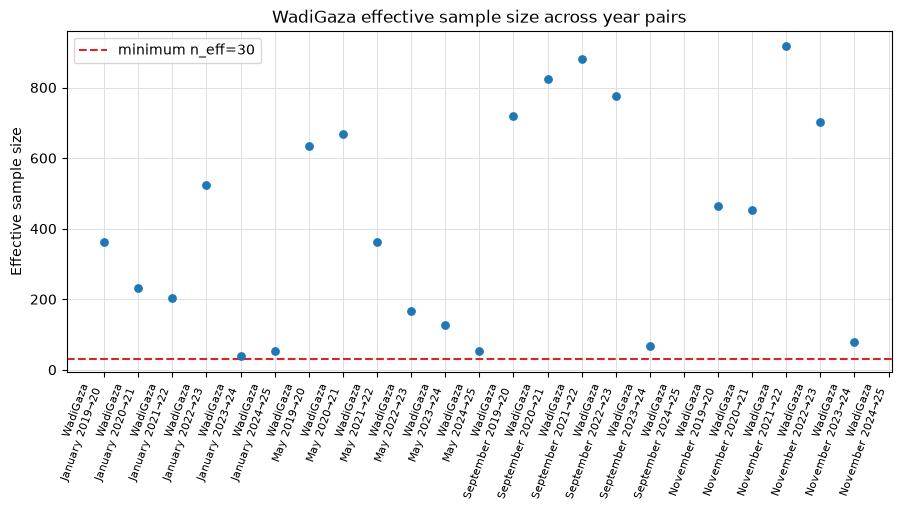

In [7]:
fig, ax = plot_n_eff(wadi, min_n_eff=30)
add_title(ax, 'WadiGaza effective sample size across year pairs')
save_figure(fig, PLOT_DIR / 'WadiGaza_effective_sample_size.png')
plt.show()

## Correlograms and threshold sensitivity for all study areas

One figure per study area and month, with one panel per year pair. Figures for every study area are saved to `plots/correlograms/`; only areas in `SHOW_AREAS` are displayed inline.

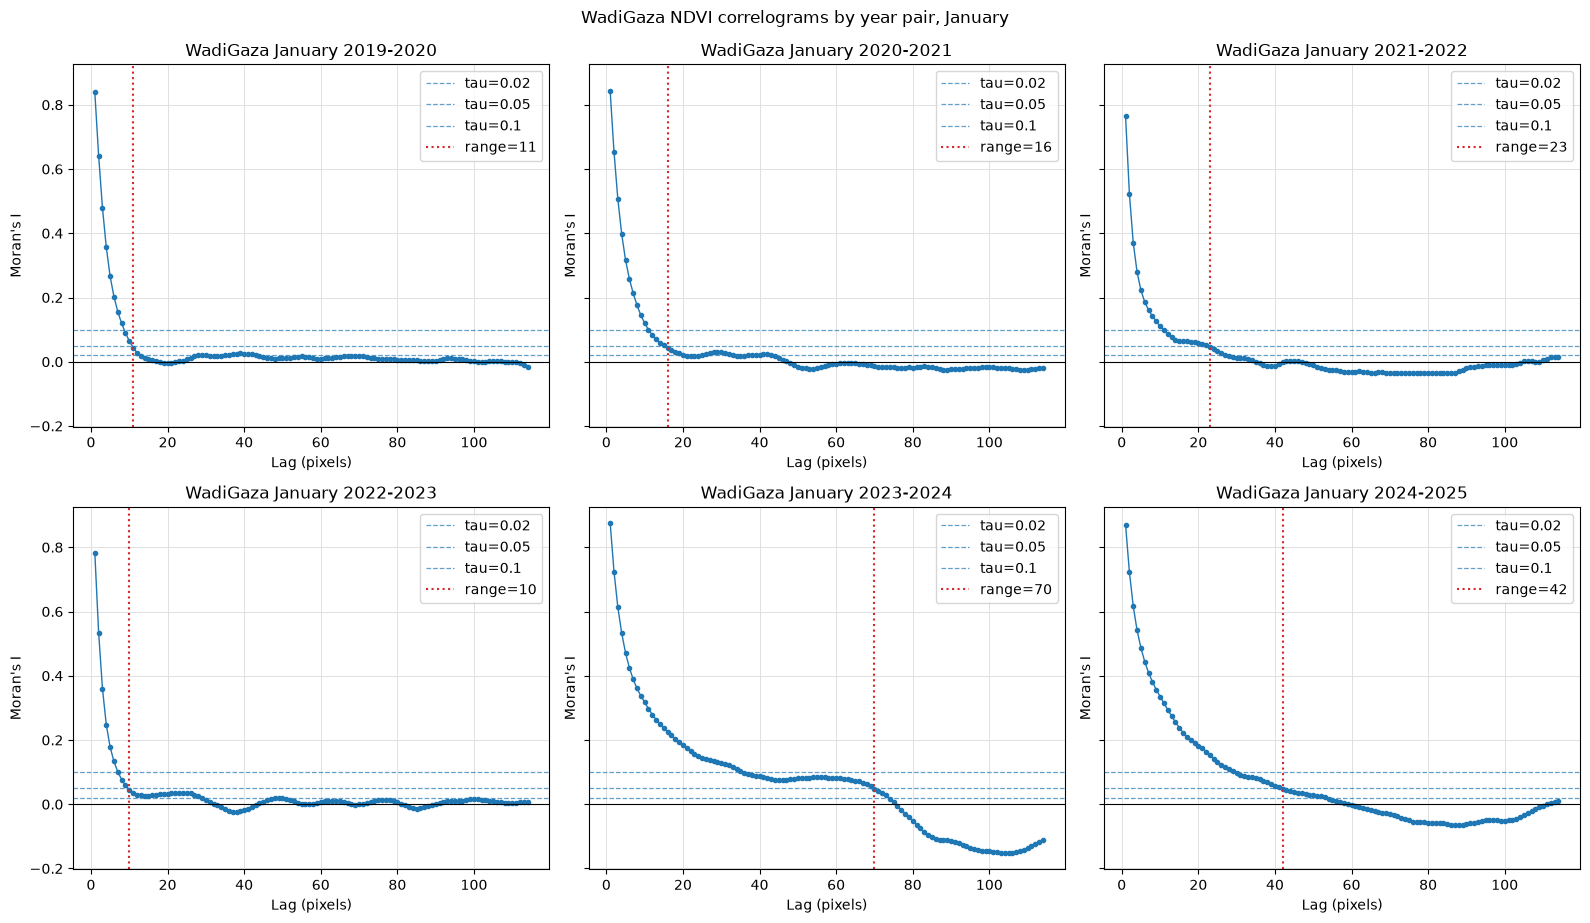

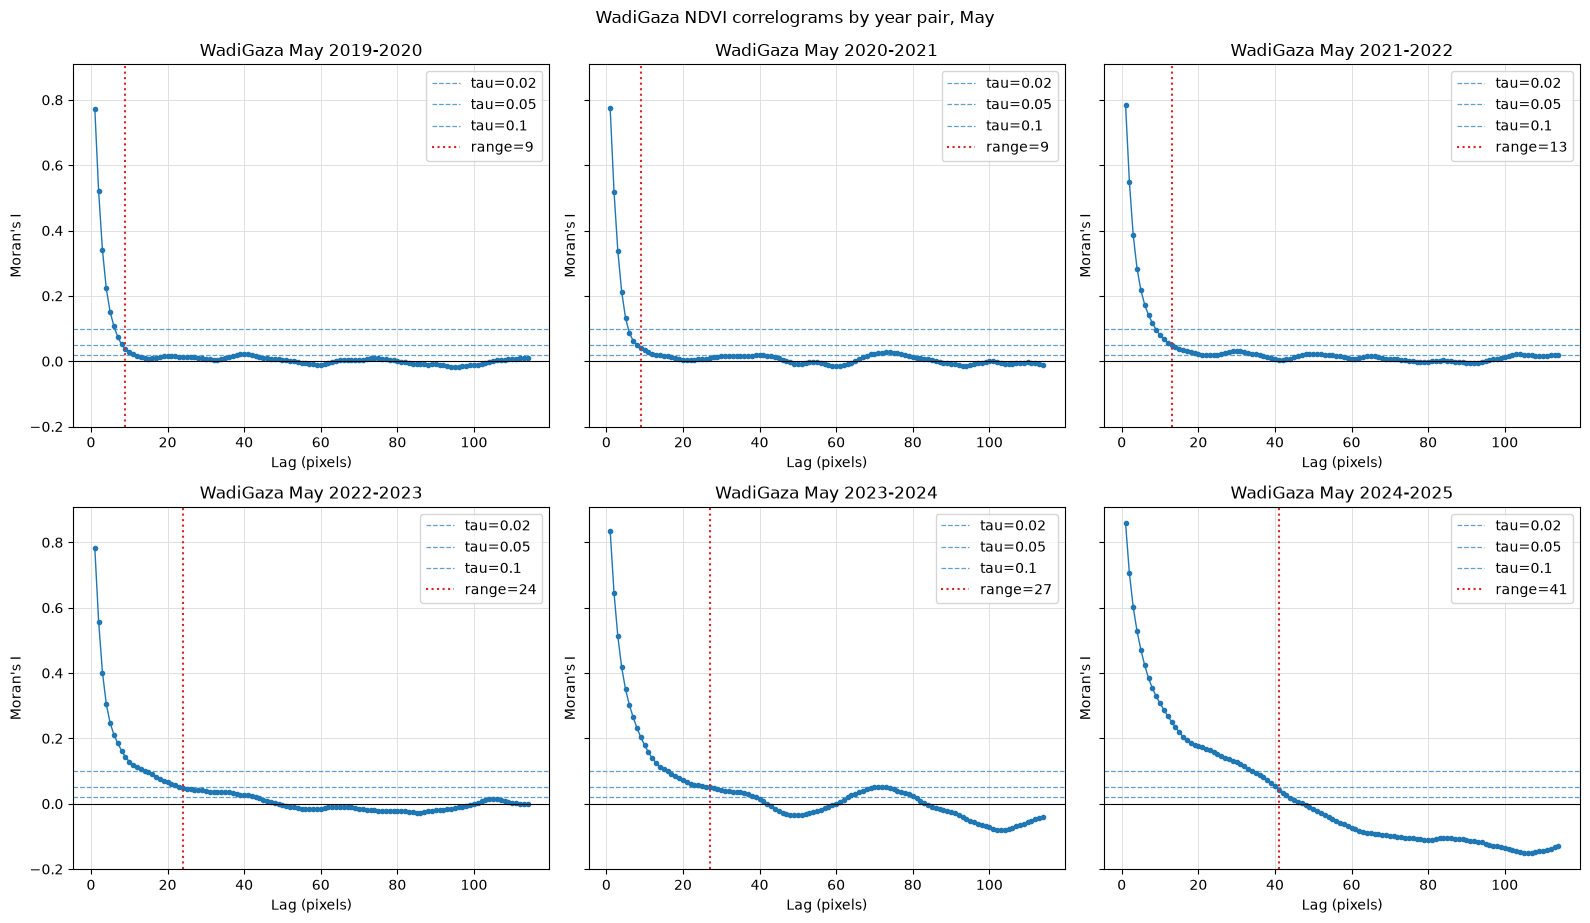

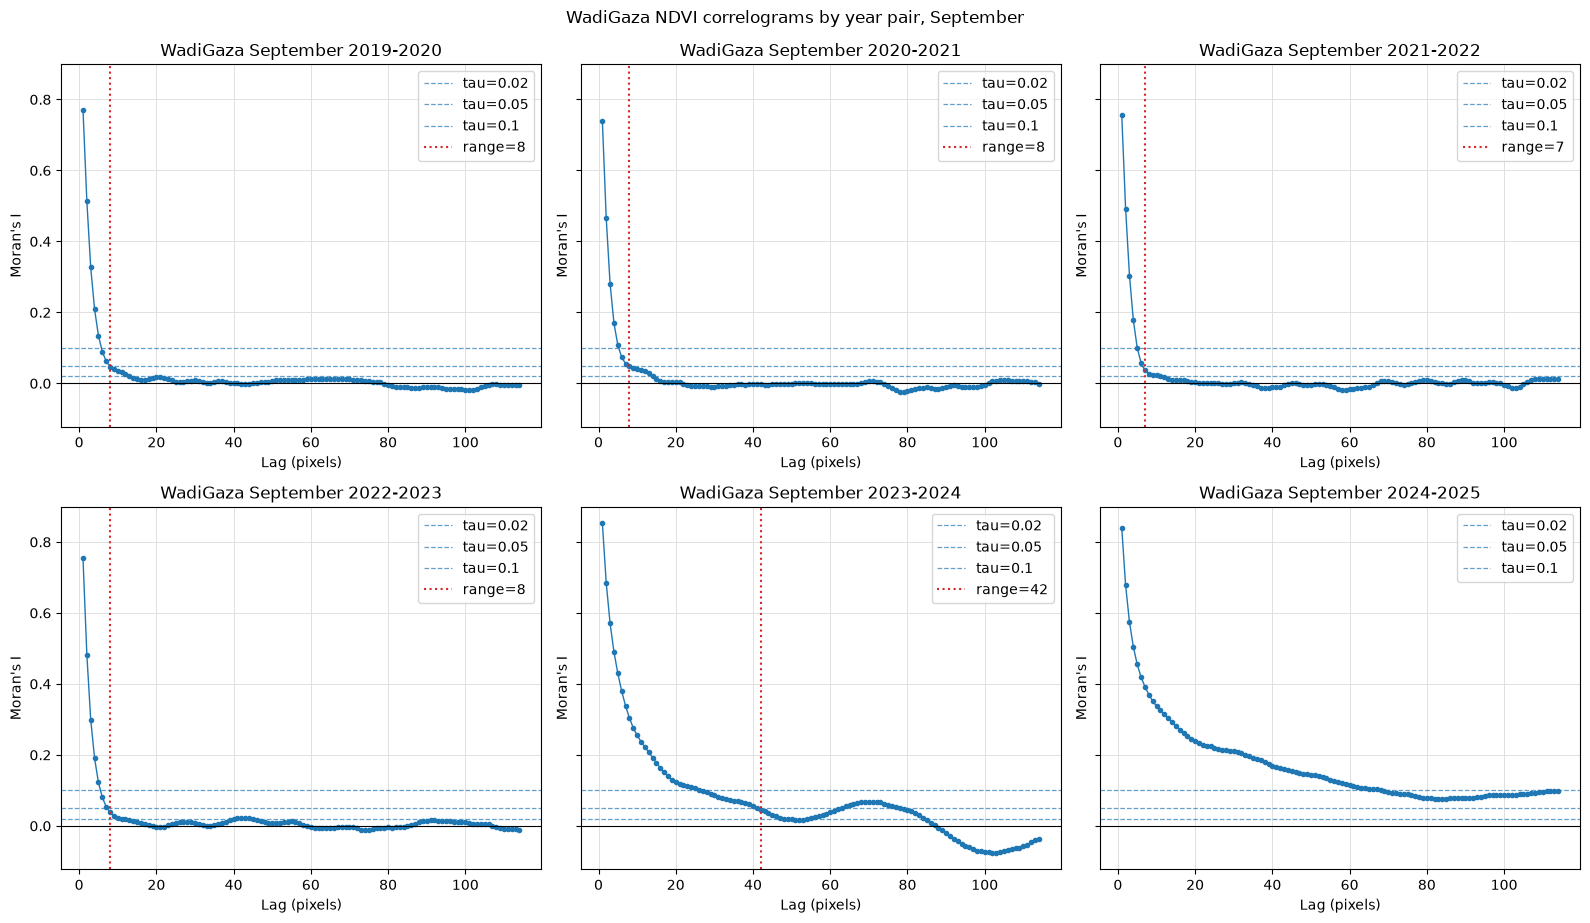

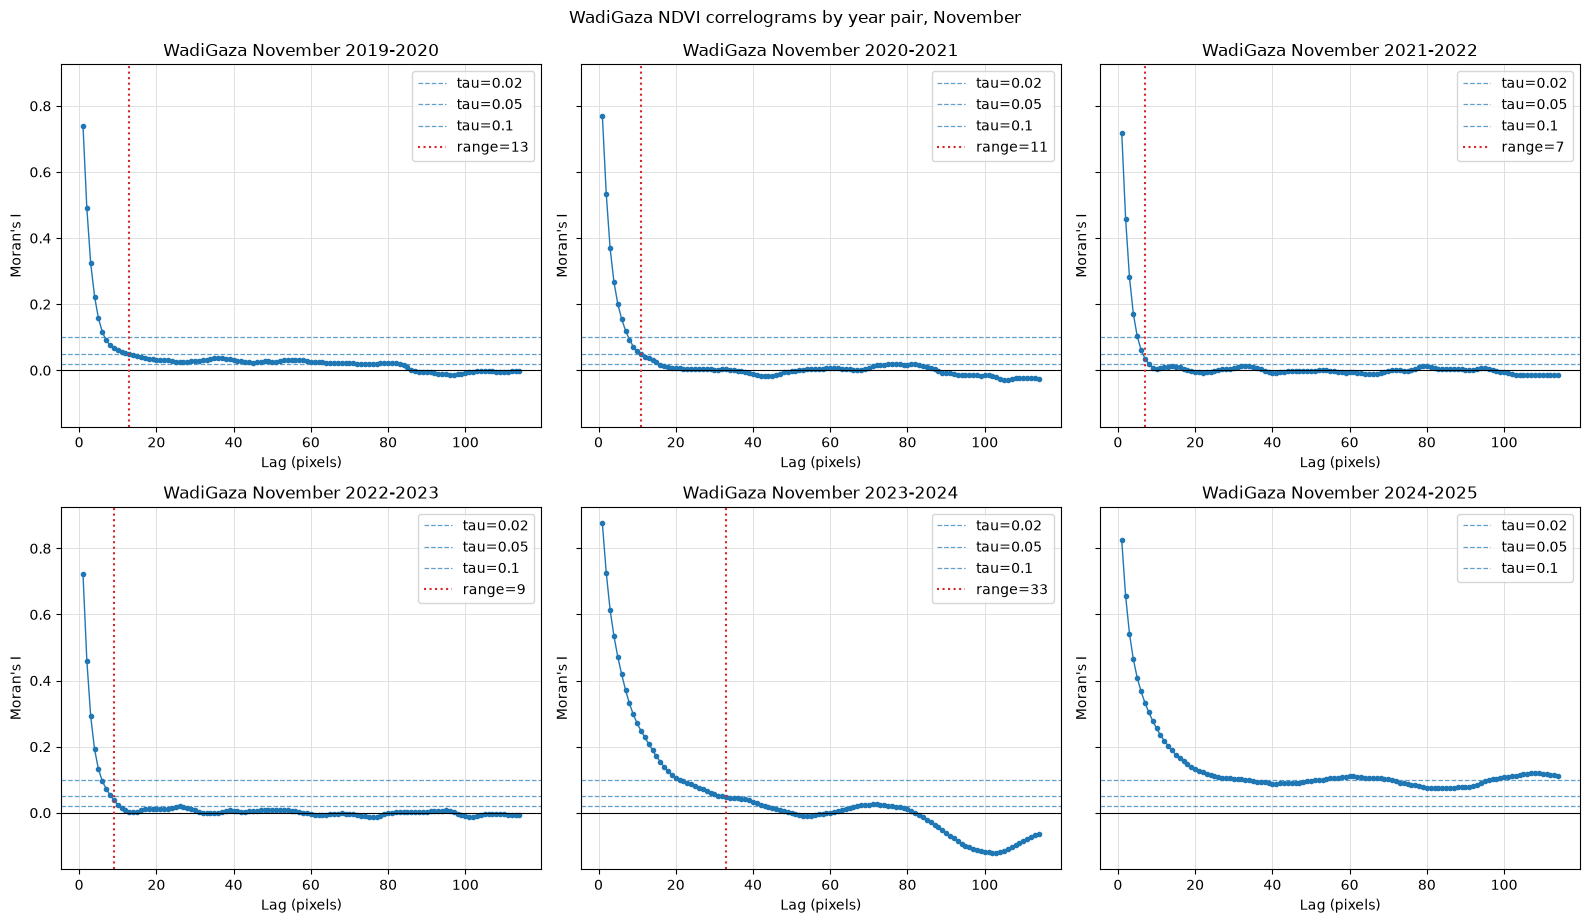

28 correlogram figures saved to /home/tshihadah/code/wadi-gaza-research/outputs/change_ci/NDVI/plots/correlograms


In [8]:
CORRELOGRAM_DIR = PLOT_DIR / 'correlograms'
SHOW_AREAS = {'WadiGaza'}  # areas displayed inline; figures for all areas are saved

study_areas = sorted(primary['study_area'].unique())
months = sorted({f'{int(m):02d}' for m in primary['month']})
year_pairs = sorted(
    (int(start), int(end))
    for start, end in primary[['year_start', 'year_end']].drop_duplicates().itertuples(index=False)
)

for study_area in study_areas:
    for month in months:
        fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
        for ax, (year_start, year_end) in zip(axes.flat, year_pairs):
            pair = {
                'study_area': study_area, 'month': month,
                'year_start': year_start, 'year_end': year_end,
            }
            try:
                plot_correlogram(correlograms, results, pair, ax=ax)
            except ValueError:
                ax.set_axis_off()
        add_title(fig, f'{study_area} {PLOT_INDEX} correlograms by year pair, {month_name(month)}', y=1.02)
        save_figure(fig, CORRELOGRAM_DIR / f'{study_area}_{month}_correlograms_all_year_pairs.png')
        if study_area in SHOW_AREAS:
            plt.show()
        else:
            plt.close(fig)

print(f'{len(study_areas) * len(months)} correlogram figures saved to {CORRELOGRAM_DIR}')

## Refresh figure captions

Generate linked caption catalogs from the maintained templates. See [caption maintenance](../docs/Figure-Captions.md).

In [9]:
from generate_figure_captions import generate_catalogs

generate_catalogs(ROOT)

Generated captions for 151 figures in 22 folders; 125 retired/unselected figures excluded.


151